# Figure 2 · Làm trơn mục tiêu huấn luyện

**Nguồn chính** · Kết quả từng lượt do tác giả công bố. Notebook chạy lại phép phân tích và vẽ hình bằng Python. Lần mở đầu cần Internet để tải và đối chiếu SHA-256.

## Cách đọc thí nghiệm

So sánh bốn mức hệ số hiệp phương sai ở figure chính. Chuẩn hóa theo phân vị 10% trên từng bộ dữ liệu. Dùng default-first, chọn bằng validation ở hạng 60 và tổng hợp qua 15 lần xáo. Khoảng trải của boxplot đến từ các lần xáo thứ tự tìm kiếm.

In [1]:
from pathlib import Path
import sys

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "src/analysis.py").is_file())
sys.path.insert(0, str(root))
from IPython.display import Image, display
import matplotlib.pyplot as plt
from src.analysis import analyze
from src.author_data import SOURCES, prepare
from src.plots import export, export_project

source = "ablations"
cache = prepare(source)
print("SHA-256 nguồn:", SOURCES[source].sha256)

SHA-256 nguồn: 25314ccb2d138dae43fd23840f729f62fba0b5f5ab559aeb3727403dedb4e429


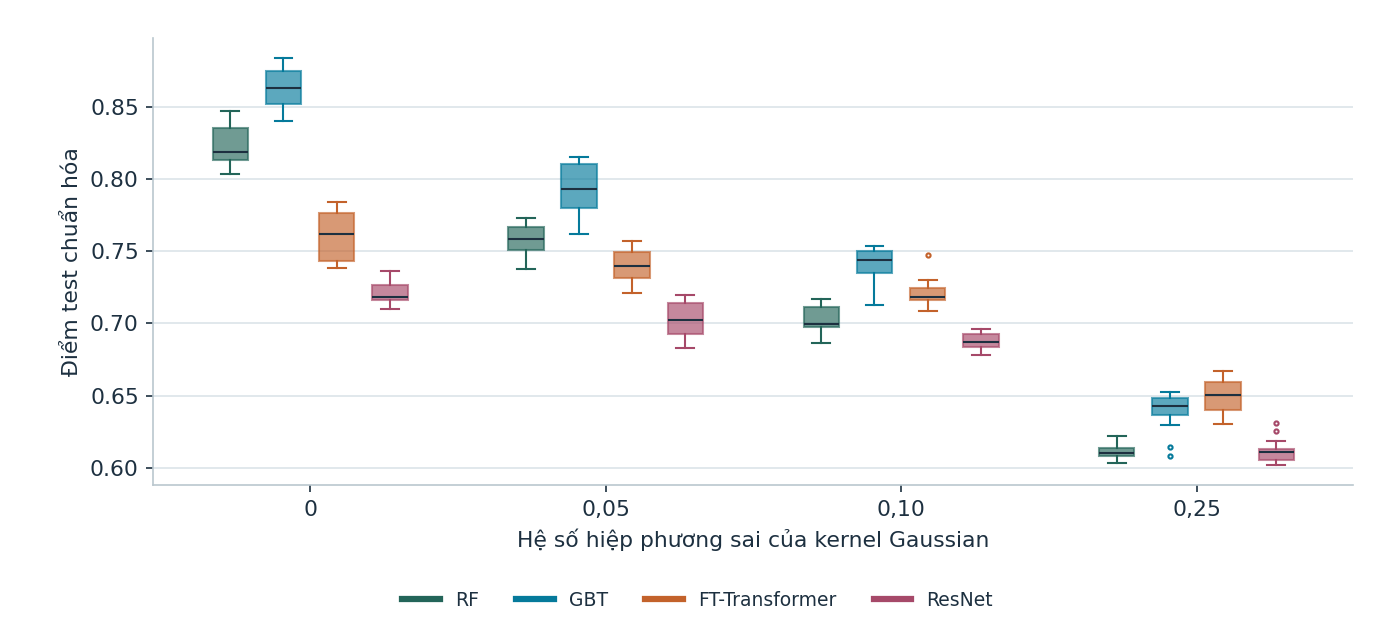

In [2]:
figure_number = 2
scores = analyze(figure_number)
chart = export(figure_number, scores)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}.png")))

## Một số giá trị đứng sau biểu đồ

In [3]:
display(scores.head(8).round(5))

,model_name,shuffle,transform__2__cov_mult,score
0,FT Transformer,1,0.00,0.77780
1,FT Transformer,1,0.05,0.72662
2,FT Transformer,1,0.10,0.71566
3,FT Transformer,1,0.25,0.65489
4,FT Transformer,2,0.00,0.73828
5,FT Transformer,2,0.05,0.72090
6,FT Transformer,2,0.10,0.72830
7,FT Transformer,2,0.25,0.66602


## Đối chứng do nhóm tự train

Pilot tự train gồm 8 lượt trên eye_movements, một seed, hai mô hình RF và MLP. Biểu đồ dưới dùng accuracy thô.

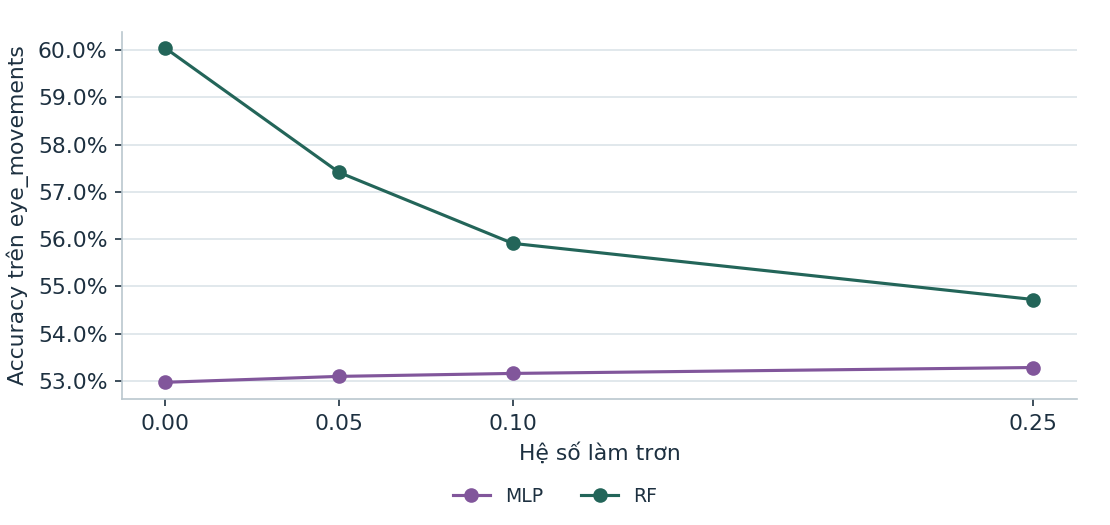

In [4]:
chart = export_project(figure_number)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}_v2.png")))

## Quy trình train trong repo tác giả

**Minh họa quy trình, không có fit mới ở notebook này.** Điểm vào: `src/launch_benchmarks/launch_xps.py · smooth_target`. Gaussian hóa, chọn 5 đặc trưng bằng RF, làm trơn nhãn train, giữ nhãn validation/test, rồi train và chấm điểm.

Nếu tái chạy độc lập, dùng cấu hình đầy đủ của đúng model, task và điều kiện từ CSV nguồn. Repo gốc có lệnh chuẩn bị môi trường, launcher và `train_model_on_config`; khóa phiên bản source trước khi chạy. 

### Ví dụ cấu hình đã công bố

Các giá trị dưới đây trích từ dòng đầu tiên của GBT trong từng nhánh, theo thứ tự CSV. File lịch sử dùng tên bộ dữ liệu và loader `real_data`. Launcher pin hiện tại dùng OpenML task ID và `openml_no_transform`, nên cần đối chiếu đầu vào khi chạy lại ví dụ.

In [5]:
import json
import pandas as pd
published = json.loads((root / "evidence/published_config_examples.json").read_text(encoding="utf-8"))
names = ('high_frequencies',)
display(pd.DataFrame({name: published["examples"][name]["settings"] for name in names}).fillna("—"))

,high_frequencies
data__keyword,covertype
data__method_name,real_data
data__regression,0
max_test_samples,50000
max_train_samples,10000
max_val_samples,50000
model__learning_rate,0.01647121448179738
model__loss,deviance
model__max_depth,4
model__min_samples_leaf,8


## Nguồn

- [Paper NeurIPS 2022](https://papers.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
- [Repo tác giả, commit đã đối chiếu](https://github.com/LeoGrin/tabular-benchmark/tree/9d54cf53d9fd3159e367e70a00005f4fcbf2c79d)
